In [ ]:
!pip install -q lifelines shap xgboost openpyxl

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 31.8 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import (
    mutual_info_classif,
    f_classif,
    RFE
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# XGBoost
from xgboost import XGBClassifier

# SHAP
import shap

# Survival
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

# Google Drive
from google.colab import drive

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
DATA_PATH = "/content/drive/MyDrive/METABRIC_RNA_Mutation.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nNumber of patients:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (1904, 693)

Number of patients: 1904
Number of columns: 693


In [ ]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First 5 rows:


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0



Column names:
['patient_id', 'age_at_diagnosis', 'type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'chemotherapy', 'pam50_+_claudin-low_subtype', 'cohort', 'er_status_measured_by_ihc', 'er_status', 'neoplasm_histologic_grade', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'hormone_therapy', 'inferred_menopausal_state', 'integrative_cluster', 'primary_tumor_laterality', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'oncotree_code', 'overall_survival_months', 'overall_survival', 'pr_status', 'radio_therapy', '3-gene_classifier_subtype', 'tumor_size', 'tumor_stage', 'death_from_cancer', 'brca1', 'brca2', 'palb2', 'pten', 'tp53', 'atm', 'cdh1', 'chek2', 'nbn', 'nf1', 'stk11', 'bard1', 'mlh1', 'msh2', 'msh6', 'pms2', 'epcam', 'rad51c', 'rad51d', 'rad50', 'rb1', 'rbl1', 'rbl2', 'ccna1', 'ccnb1', 'cdk1', 'ccne1', 'cdk2', 'cdc25a', 'ccnd1', 'cdk4', 'cdk6', 'ccnd2', 'cdkn2a', 'cdkn2b', 'myc', '

In [ ]:
important_columns = [
    "patient_id",
    "overall_survival_months",
    "overall_survival",
    "death_from_cancer",
    "pam50_+_claudin-low_subtype",
    "3-gene_classifier_subtype"
]

for col in important_columns:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print("Missing:", df[col].isna().sum())
        print("Unique values:", df[col].dropna().unique()[:20])


patient_id
Data type: int64
Missing: 0
Unique values: [ 0  2  5  6  8 10 14 22 28 35 36 39 45 46 48 50 53 54 56 60]

overall_survival_months
Data type: float64
Missing: 0
Unique values: [140.5         84.63333333 163.7        164.9333333   41.36666667
   7.8        164.3333333   99.53333333  36.56666667  36.26666667
 132.0333333  163.5333333  164.9         14.13333333 103.8333333
  75.33333333 161.0666667  160.3         62.86666667 140.8666667 ]

overall_survival
Data type: int64
Missing: 0
Unique values: [1 0]

death_from_cancer
Data type: object
Missing: 1
Unique values: ['Living' 'Died of Disease' 'Died of Other Causes']

pam50_+_claudin-low_subtype
Data type: object
Missing: 0
Unique values: ['claudin-low' 'LumA' 'LumB' 'Her2' 'Normal' 'Basal' 'NC']

3-gene_classifier_subtype
Data type: object
Missing: 204
Unique values: ['ER-/HER2-' 'ER+/HER2- High Prolif' 'ER+/HER2- Low Prolif' 'HER2+']


In [ ]:
SURVIVAL_TIME = "overall_survival_months"
SURVIVAL_STATUS = "overall_survival"

SUBTYPE_TARGET = "pam50_+_claudin-low_subtype"

print("Survival time:", SURVIVAL_TIME)
print("Survival status:", SURVIVAL_STATUS)
print("Subtype target:", SUBTYPE_TARGET)

Survival time: overall_survival_months
Survival status: overall_survival
Subtype target: pam50_+_claudin-low_subtype


In [ ]:
df["event"] = 1 - df[SURVIVAL_STATUS]

print(df["event"].value_counts())

event
1    1103
0     801
Name: count, dtype: int64


In [ ]:
survival_df = df[
    df[SURVIVAL_TIME].notna() &
    df["event"].notna()
].copy()

print("Original patients:", len(df))
print("Patients with survival information:", len(survival_df))

Original patients: 1904
Patients with survival information: 1904


In [ ]:
clinical_features = [
    "age_at_diagnosis",
    "type_of_breast_surgery",
    "cancer_type",
    "cancer_type_detailed",
    "cellularity",
    "chemotherapy",
    "er_status_measured_by_ihc",
    "er_status",
    "neoplasm_histologic_grade",
    "her2_status_measured_by_snp6",
    "her2_status",
    "tumor_other_histologic_subtype",
    "hormone_therapy",
    "inferred_menopausal_state",
    "primary_tumor_laterality",
    "lymph_nodes_examined_positive",
    "nottingham_prognostic_index",
    "pr_status",
    "radio_therapy",
    "tumor_size",
    "tumor_stage"
]

clinical_features = [
    col for col in clinical_features
    if col in df.columns
]

print("Number of clinical features:", len(clinical_features))
print(clinical_features)

Number of clinical features: 21
['age_at_diagnosis', 'type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'chemotherapy', 'er_status_measured_by_ihc', 'er_status', 'neoplasm_histologic_grade', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'hormone_therapy', 'inferred_menopausal_state', 'primary_tumor_laterality', 'lymph_nodes_examined_positive', 'nottingham_prognostic_index', 'pr_status', 'radio_therapy', 'tumor_size', 'tumor_stage']


In [ ]:
mutation_features = [
    col for col in df.columns
    if col.endswith("_mut")
]

print("Number of mutation features:", len(mutation_features))
print("\nFirst 50 mutation features:")
print(mutation_features[:50])

Number of mutation features: 173

First 50 mutation features:
['pik3ca_mut', 'tp53_mut', 'muc16_mut', 'ahnak2_mut', 'kmt2c_mut', 'syne1_mut', 'gata3_mut', 'map3k1_mut', 'ahnak_mut', 'dnah11_mut', 'cdh1_mut', 'dnah2_mut', 'kmt2d_mut', 'ush2a_mut', 'ryr2_mut', 'dnah5_mut', 'herc2_mut', 'pde4dip_mut', 'akap9_mut', 'tg_mut', 'birc6_mut', 'utrn_mut', 'tbx3_mut', 'col6a3_mut', 'arid1a_mut', 'lama2_mut', 'notch1_mut', 'cbfb_mut', 'ncor2_mut', 'col12a1_mut', 'col22a1_mut', 'pten_mut', 'akt1_mut', 'atr_mut', 'thada_mut', 'ncor1_mut', 'stab2_mut', 'myh9_mut', 'runx1_mut', 'nf1_mut', 'map2k4_mut', 'ros1_mut', 'lamb3_mut', 'arid1b_mut', 'erbb2_mut', 'sf3b1_mut', 'shank2_mut', 'ep300_mut', 'ptprd_mut', 'usp9x_mut']


In [ ]:
excluded_columns = set(
    clinical_features
    + mutation_features
    + [
        "patient_id",
        "cohort",
        "integrative_cluster",
        "oncotree_code",
        "overall_survival_months",
        "overall_survival",
        "death_from_cancer",
        "event",
        "pam50_+_claudin-low_subtype",
        "3-gene_classifier_subtype"
    ]
)

possible_gene_features = [
    col for col in df.columns
    if col not in excluded_columns
]

print("Possible gene-expression features:", len(possible_gene_features))

print("\nFirst 100 possible gene features:")
print(possible_gene_features[:100])

Possible gene-expression features: 490

First 100 possible gene features:
['mutation_count', 'brca1', 'brca2', 'palb2', 'pten', 'tp53', 'atm', 'cdh1', 'chek2', 'nbn', 'nf1', 'stk11', 'bard1', 'mlh1', 'msh2', 'msh6', 'pms2', 'epcam', 'rad51c', 'rad51d', 'rad50', 'rb1', 'rbl1', 'rbl2', 'ccna1', 'ccnb1', 'cdk1', 'ccne1', 'cdk2', 'cdc25a', 'ccnd1', 'cdk4', 'cdk6', 'ccnd2', 'cdkn2a', 'cdkn2b', 'myc', 'cdkn1a', 'cdkn1b', 'e2f1', 'e2f2', 'e2f3', 'e2f4', 'e2f5', 'e2f6', 'e2f7', 'e2f8', 'src', 'jak1', 'jak2', 'stat1', 'stat2', 'stat3', 'stat5a', 'stat5b', 'mdm2', 'tp53bp1', 'adam10', 'adam17', 'aph1a', 'aph1b', 'arrdc1', 'cir1', 'ctbp1', 'ctbp2', 'cul1', 'dll1', 'dll3', 'dll4', 'dtx1', 'dtx2', 'dtx3', 'dtx4', 'ep300', 'fbxw7', 'hdac1', 'hdac2', 'hes1', 'hes5', 'heyl', 'itch', 'jag1', 'jag2', 'kdm5a', 'lfng', 'maml1', 'maml2', 'maml3', 'ncor2', 'ncstn', 'notch1', 'notch2', 'notch3', 'nrarp', 'numb', 'numbl', 'psen1', 'psen2', 'psenen', 'rbpj']


In [ ]:
print("All possible genomic columns:")
for i, col in enumerate(possible_gene_features):
    print(i, col)

All possible genomic columns:
0 mutation_count
1 brca1
2 brca2
3 palb2
4 pten
5 tp53
6 atm
7 cdh1
8 chek2
9 nbn
10 nf1
11 stk11
12 bard1
13 mlh1
14 msh2
15 msh6
16 pms2
17 epcam
18 rad51c
19 rad51d
20 rad50
21 rb1
22 rbl1
23 rbl2
24 ccna1
25 ccnb1
26 cdk1
27 ccne1
28 cdk2
29 cdc25a
30 ccnd1
31 cdk4
32 cdk6
33 ccnd2
34 cdkn2a
35 cdkn2b
36 myc
37 cdkn1a
38 cdkn1b
39 e2f1
40 e2f2
41 e2f3
42 e2f4
43 e2f5
44 e2f6
45 e2f7
46 e2f8
47 src
48 jak1
49 jak2
50 stat1
51 stat2
52 stat3
53 stat5a
54 stat5b
55 mdm2
56 tp53bp1
57 adam10
58 adam17
59 aph1a
60 aph1b
61 arrdc1
62 cir1
63 ctbp1
64 ctbp2
65 cul1
66 dll1
67 dll3
68 dll4
69 dtx1
70 dtx2
71 dtx3
72 dtx4
73 ep300
74 fbxw7
75 hdac1
76 hdac2
77 hes1
78 hes5
79 heyl
80 itch
81 jag1
82 jag2
83 kdm5a
84 lfng
85 maml1
86 maml2
87 maml3
88 ncor2
89 ncstn
90 notch1
91 notch2
92 notch3
93 nrarp
94 numb
95 numbl
96 psen1
97 psen2
98 psenen
99 rbpj
100 rbpjl
101 rfng
102 snw1
103 spen
104 hes2
105 hes4
106 hes7
107 hey1
108 hey2
109 acvr1
110 acvr1b
111 

In [ ]:
gene_features = possible_gene_features.copy()

print("Final gene-expression feature count:", len(gene_features))

Final gene-expression feature count: 490


In [ ]:
subtype_df = df[
    df[SUBTYPE_TARGET].notna()
].copy()

X_genes = subtype_df[gene_features].copy()
y_subtype = subtype_df[SUBTYPE_TARGET].copy()

print("X shape:", X_genes.shape)
print("y shape:", y_subtype.shape)

print("\nSubtype distribution:")
print(y_subtype.value_counts())

X shape: (1904, 490)
y shape: (1904,)

Subtype distribution:
pam50_+_claudin-low_subtype
LumA           679
LumB           461
Her2           220
claudin-low    199
Basal          199
Normal         140
NC               6
Name: count, dtype: int64


In [ ]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y_subtype)

print("Subtype classes:")
for i, cls in enumerate(label_encoder.classes_):
    print(i, "=", cls)

Subtype classes:
0 = Basal
1 = Her2
2 = LumA
3 = LumB
4 = NC
5 = Normal
6 = claudin-low


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_genes,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (1523, 490)
Testing shape: (381, 490)


In [ ]:
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

print("Training matrix:", X_train_imp.shape)
print("Testing matrix:", X_test_imp.shape)

Training matrix: (1523, 490)
Testing matrix: (381, 490)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Scaling completed.")

Scaling completed.


In [ ]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train_imp, y_train)

rf_importance = rf.feature_importances_

rf_results = pd.DataFrame({
    "feature": gene_features,
    "RandomForest": rf_importance
})

rf_results = rf_results.sort_values(
    "RandomForest",
    ascending=False
)

print(rf_results.head(20))

    feature  RandomForest
153    egfr      0.017553
281   gata3      0.016959
121   aurka      0.011837
269  tgfbr2      0.011636
145   csf1r      0.010981
27    ccne1      0.010631
303    mapt      0.010618
157   erbb2      0.009937
26     cdk1      0.009816
175   igf1r      0.009317
423   ttyh1      0.008398
435      ar      0.008351
164   folr2      0.008128
143   chek1      0.008056
29   cdc25a      0.007314
359   lama2      0.007306
123    bcl2      0.006605
224    mmp7      0.006581
40     e2f2      0.006570
267   tgfb3      0.006527


In [ ]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train_imp, y_train)

xgb_importance = xgb.feature_importances_

xgb_results = pd.DataFrame({
    "feature": gene_features,
    "XGBoost": xgb_importance
})

xgb_results = xgb_results.sort_values(
    "XGBoost",
    ascending=False
)

print(xgb_results.head(20))

      feature   XGBoost
281     gata3  0.019554
121     aurka  0.016278
153      egfr  0.013904
145     csf1r  0.013832
26       cdk1  0.010100
157     erbb2  0.009630
41       e2f3  0.009030
123      bcl2  0.008909
452  hsd17b11  0.008849
303      mapt  0.008525
27      ccne1  0.007932
360     lamb3  0.007920
158     erbb3  0.007871
170     gsk3b  0.007735
269    tgfbr2  0.006655
257     smad4  0.006584
33      ccnd2  0.006164
377     nr2f1  0.006156
29     cdc25a  0.005658
143     chek1  0.005614


In [ ]:
gain_dict = xgb.get_booster().get_score(
    importance_type="gain"
)

gain_results = pd.DataFrame({
    "feature": gene_features,
    "XGBoost_Gain": [
        gain_dict.get(feature, 0)
        for feature in gene_features
    ]
})

gain_results = gain_results.sort_values(
    "XGBoost_Gain",
    ascending=False
)

print(gain_results.head(20))

            feature  XGBoost_Gain
489          ugt2b7             0
0    mutation_count             0
1             brca1             0
2             brca2             0
3             palb2             0
4              pten             0
5              tp53             0
6               atm             0
7              cdh1             0
8             chek2             0
450         hsd17b1             0
451        hsd17b10             0
452        hsd17b11             0
453        hsd17b12             0
454        hsd17b13             0
455        hsd17b14             0
456         hsd17b2             0
457         hsd17b3             0
442         cyp17a1             0
443         cyp19a1             0


In [ ]:
perm = permutation_importance(
    xgb,
    X_test_imp,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_results = pd.DataFrame({
    "feature": gene_features,
    "Permutation": perm.importances_mean
})

permutation_results = permutation_results.sort_values(
    "Permutation",
    ascending=False
)

print(permutation_results.head(20))

    feature  Permutation
153    egfr     0.030886
157   erbb2     0.022374
360   lamb3     0.015262
26     cdk1     0.011926
145   csf1r     0.010781
123    bcl2     0.009486
163   folr1     0.008786
479   spry2     0.006375
121   aurka     0.006352
42     e2f4     0.005566
347   frmd3     0.004593
175   igf1r     0.004510
359   lama2     0.003798
122     bad     0.003692
301    map2     0.003678
257   smad4     0.002725
143   chek1     0.002703
36      myc     0.002580
423   ttyh1     0.002556
336  ctnna1     0.002485


In [ ]:
explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test_imp)

In [ ]:
if isinstance(shap_values, list):

    shap_array = np.array(shap_values)

    shap_importance = np.mean(
        np.abs(shap_array),
        axis=(0, 1)
    )

else:

    shap_array = np.array(shap_values)

    if shap_array.ndim == 3:
        shap_importance = np.mean(
            np.abs(shap_array),
            axis=(0, 2)
        )
    else:
        shap_importance = np.mean(
            np.abs(shap_array),
            axis=0
        )

shap_results = pd.DataFrame({
    "feature": gene_features,
    "SHAP": shap_importance
})

shap_results = shap_results.sort_values(
    "SHAP",
    ascending=False
)

print(shap_results.head(20))

    feature      SHAP
153    egfr  0.225758
281   gata3  0.172429
145   csf1r  0.148286
157   erbb2  0.130858
158   erbb3  0.130049
26     cdk1  0.115599
360   lamb3  0.108596
121   aurka  0.101217
27    ccne1  0.097947
303    mapt  0.097076
163   folr1  0.092153
143   chek1  0.087336
90   notch1  0.064079
479   spry2  0.064028
270  tgfbr3  0.057749
359   lama2  0.054884
423   ttyh1  0.054805
183     kit  0.053203
29   cdc25a  0.051507
40     e2f2  0.048756


In [ ]:
lasso = LogisticRegression(
    penalty="l1",
    solver="saga",
    max_iter=3000,
    C=0.1,
    multi_class="auto",
    random_state=42
)

lasso.fit(X_train_scaled, y_train)

lasso_coef = np.abs(lasso.coef_)

lasso_importance = np.mean(
    lasso_coef,
    axis=0
)

lasso_results = pd.DataFrame({
    "feature": gene_features,
    "LASSO": lasso_importance
})

lasso_results = lasso_results.sort_values(
    "LASSO",
    ascending=False
)

print(lasso_results.head(20))

    feature     LASSO
153    egfr  0.152340
26     cdk1  0.131229
157   erbb2  0.126290
183     kit  0.115580
145   csf1r  0.102902
468   nrip1  0.088853
158   erbb3  0.084154
143   chek1  0.081725
97    psen2  0.081461
360   lamb3  0.079430
479   spry2  0.078846
224    mmp7  0.074703
281   gata3  0.071055
40     e2f2  0.068803
480  srd5a1  0.067744
359   lama2  0.062681
241   rab25  0.062295
25    ccnb1  0.061852
55     mdm2  0.059906
36      myc  0.057170


In [ ]:
elastic_net = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    l1_ratio=0.5,
    C=0.1,
    max_iter=3000,
    multi_class="auto",
    random_state=42
)

elastic_net.fit(X_train_scaled, y_train)

elastic_coef = np.abs(elastic_net.coef_)

elastic_importance = np.mean(
    elastic_coef,
    axis=0
)

elastic_results = pd.DataFrame({
    "feature": gene_features,
    "ElasticNet": elastic_importance
})

elastic_results = elastic_results.sort_values(
    "ElasticNet",
    ascending=False
)

print(elastic_results.head(20))

    feature  ElasticNet
153    egfr    0.150534
157   erbb2    0.146517
26     cdk1    0.132371
183     kit    0.124977
468   nrip1    0.113282
224    mmp7    0.110605
480  srd5a1    0.101161
25    ccnb1    0.097533
97    psen2    0.089905
143   chek1    0.088290
145   csf1r    0.087405
479   spry2    0.082420
360   lamb3    0.081347
158   erbb3    0.077978
320   arid2    0.074021
359   lama2    0.072917
54   stat5b    0.070920
55     mdm2    0.070462
40     e2f2    0.069696
291   abcb1    0.068955


In [ ]:
mi_scores = mutual_info_classif(
    X_train_imp,
    y_train,
    random_state=42
)

mi_results = pd.DataFrame({
    "feature": gene_features,
    "MutualInformation": mi_scores
})

mi_results = mi_results.sort_values(
    "MutualInformation",
    ascending=False
)

print(mi_results.head(20))

    feature  MutualInformation
281   gata3           0.380461
153    egfr           0.376572
121   aurka           0.305833
27    ccne1           0.293397
303    mapt           0.275719
143   chek1           0.270061
60    aph1b           0.265886
29   cdc25a           0.263925
157   erbb2           0.237551
175   igf1r           0.230387
32     cdk6           0.226098
40     e2f2           0.225111
123    bcl2           0.220798
158   erbb3           0.220155
224    mmp7           0.210811
423   ttyh1           0.209208
26     cdk1           0.208822
41     e2f3           0.206591
435      ar           0.194767
90   notch1           0.191592


In [ ]:
f_scores, p_values = f_classif(
    X_train_imp,
    y_train
)

anova_results = pd.DataFrame({
    "feature": gene_features,
    "ANOVA_F": f_scores
})

anova_results = anova_results.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

anova_results = anova_results.sort_values(
    "ANOVA_F",
    ascending=False
)

print(anova_results.head(20))

    feature     ANOVA_F
281   gata3  372.822831
303    mapt  207.179575
27    ccne1  203.089897
143   chek1  170.774345
121   aurka  164.199256
29   cdc25a  156.207388
158   erbb3  155.064726
153    egfr  149.905716
123    bcl2  147.489535
40     e2f2  140.980587
32     cdk6  139.014816
41     e2f3  137.810916
423   ttyh1  136.414411
26     cdk1  133.723168
60    aph1b  129.451698
175   igf1r  128.825780
435      ar  125.103626
90   notch1  122.661383
34   cdkn2a  110.640128
480  srd5a1  108.847091


In [ ]:
top_xgb_features = (
    xgb_results
    .head(100)["feature"]
    .tolist()
)

top_xgb_indices = [
    gene_features.index(feature)
    for feature in top_xgb_features
]

X_train_rfe = X_train_scaled[:, top_xgb_indices]

rfe_estimator = LogisticRegression(
    penalty="l2",
    max_iter=3000,
    solver="lbfgs",
    multi_class="auto"
)

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=20,
    step=10
)

rfe.fit(
    X_train_rfe,
    y_train
)

rfe_results = pd.DataFrame({
    "feature": top_xgb_features,
    "RFE": rfe.support_.astype(int)
})

rfe_results = rfe_results.sort_values(
    "RFE",
    ascending=False
)

print(rfe_results.head(30))

     feature  RFE
0      gata3    1
2       egfr    1
3      csf1r    1
4       cdk1    1
33   hsd17b4    1
8   hsd17b11    1
14    tgfbr2    1
12     erbb3    1
16     ccnd2    1
18    cdc25a    1
23     frmd3    1
20     klrg1    1
27     lama2    1
94      akt1    1
68    notch1    1
59      mmp7    1
54     ttyh1    1
40     spry2    1
43     folr2    1
42     ccnb1    1
19     chek1    0
17     nr2f1    0
13     gsk3b    0
15     smad4    0
22    tgfbr3    0
24     igf1r    0
25     abcb1    0
21      lfng    0
26       fn1    0
1      aurka    0


In [ ]:
importance_df = rf_results.copy()

importance_df = importance_df.merge(
    xgb_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    gain_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    permutation_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    shap_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    lasso_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    elastic_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    mi_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    anova_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.merge(
    rfe_results,
    on="feature",
    how="outer"
)

importance_df = importance_df.fillna(0)

print("Combined feature-importance table:")
display(importance_df.head())
print("Shape:", importance_df.shape)

Combined feature-importance table:


,feature,RandomForest,XGBoost,XGBoost_Gain,Permutation,SHAP,LASSO,ElasticNet,MutualInformation,ANOVA_F,RFE
0,abcb1,0.006427,0.004528,0,0.002159,0.037459,0.045352,0.068955,0.161138,91.002575,0.0
1,abcb11,0.001312,0.001517,0,-0.000006,0.003520,0.007337,0.012903,0.000973,1.614474,0.0
2,abcc1,0.000890,0.000977,0,0.000000,0.003187,0.000000,0.000000,0.045485,12.544832,0.0
3,abcc10,0.001402,0.001662,0,0.000000,0.002787,0.000000,0.000000,0.088451,47.535943,0.0
4,ackr3,0.002623,0.001084,0,-0.000012,0.022556,0.000727,0.019593,0.025303,15.723981,0.0


Shape: (490, 11)


In [ ]:
importance_methods = [
    "RandomForest",
    "XGBoost",
    "XGBoost_Gain",
    "Permutation",
    "SHAP",
    "LASSO",
    "ElasticNet",
    "MutualInformation",
    "ANOVA_F",
    "RFE"
]

for method in importance_methods:

    min_val = importance_df[method].min()
    max_val = importance_df[method].max()

    if max_val > min_val:
        importance_df[method + "_normalized"] = (
            (importance_df[method] - min_val)
            / (max_val - min_val)
        )
    else:
        importance_df[method + "_normalized"] = 0

In [ ]:
normalized_columns = [
    method + "_normalized"
    for method in importance_methods
]

importance_df["Consensus_Score"] = (
    importance_df[normalized_columns]
    .mean(axis=1)
)

importance_df = importance_df.sort_values(
    "Consensus_Score",
    ascending=False
).reset_index(drop=True)

importance_df["Consensus_Rank"] = (
    importance_df.index + 1
)

display(
    importance_df[
        [
            "Consensus_Rank",
            "feature",
            "Consensus_Score"
        ] + importance_methods
    ].head(30)
)

,Consensus_Rank,feature,Consensus_Score,RandomForest,XGBoost,XGBoost_Gain,Permutation,SHAP,LASSO,ElasticNet,MutualInformation,ANOVA_F,RFE
0,1,egfr,0.809863,0.017553,0.013904,0,0.030886,0.225758,0.152340,0.150534,0.376572,149.905716,1.0
1,2,gata3,0.665170,0.016959,0.019554,0,-0.000546,0.172429,0.071055,0.050671,0.380461,372.822831,1.0
2,3,cdk1,0.567962,0.009816,0.010100,0,0.011926,0.115599,0.131229,0.132371,0.208822,133.723168,1.0
3,4,csf1r,0.514149,0.010981,0.013832,0,0.010781,0.148286,0.102902,0.087405,0.116786,63.900051,1.0
4,5,erbb2,0.502867,0.009937,0.009630,0,0.022374,0.130858,0.126290,0.146517,0.237551,84.987333,0.0
5,6,erbb3,0.449620,0.006378,0.007871,0,-0.000396,0.130049,0.084154,0.077978,0.220155,155.064726,1.0
6,7,aurka,0.390348,0.011837,0.016278,0,0.006352,0.101217,0.026795,0.034838,0.305833,164.199256,0.0
7,8,mmp7,0.383134,0.006581,0.002889,0,0.000138,0.032629,0.074703,0.110605,0.210811,106.189627,1.0
8,9,cdc25a,0.378022,0.007314,0.005658,0,-0.002934,0.051507,0.054684,0.053637,0.263925,156.207388,1.0
9,10,lama2,0.362341,0.007306,0.004273,0,0.003798,0.054884,0.062681,0.072917,0.158380,85.021453,1.0


In [ ]:
TOP_K = 50

selection_frequency = []

for feature in importance_df["feature"]:

    count = 0

    for method in importance_methods:

        method_ranked = (
            importance_df
            .sort_values(method, ascending=False)
            .head(TOP_K)["feature"]
            .values
        )

        if feature in method_ranked:
            count += 1

    selection_frequency.append(count)

importance_df["Selection_Frequency"] = selection_frequency

In [ ]:
importance_df = importance_df.sort_values(
    ["Selection_Frequency", "Consensus_Score"],
    ascending=[False, False]
).reset_index(drop=True)

importance_df["Final_Rank"] = (
    importance_df.index + 1
)

display(
    importance_df[
        [
            "Final_Rank",
            "feature",
            "Consensus_Score",
            "Selection_Frequency"
        ]
    ].head(30)
)

,Final_Rank,feature,Consensus_Score,Selection_Frequency
0,1,egfr,0.809863,10
1,2,cdk1,0.567962,10
2,3,gata3,0.665170,9
3,4,erbb2,0.502867,9
4,5,erbb3,0.449620,9
5,6,cdc25a,0.378022,9
6,7,lama2,0.362341,9
7,8,csf1r,0.514149,8
8,9,mmp7,0.383134,8
9,10,chek1,0.360156,8


In [ ]:
TOP_N_GENES = 5

top5_genes = (
    importance_df
    .head(TOP_N_GENES)["feature"]
    .tolist()
)

print("Top 5 candidate genes:")
for i, gene in enumerate(top5_genes, 1):
    print(i, gene)

Top 5 candidate genes:
1 egfr
2 cdk1
3 gata3
4 erbb2
5 erbb3


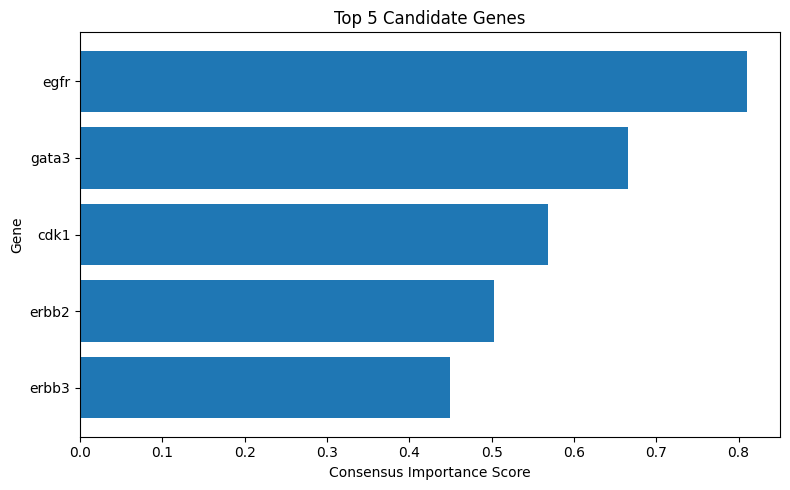

In [ ]:
top5_plot = (
    importance_df
    .head(5)
    .sort_values("Consensus_Score")
)

plt.figure(figsize=(8, 5))

plt.barh(
    top5_plot["feature"],
    top5_plot["Consensus_Score"]
)

plt.xlabel("Consensus Importance Score")
plt.ylabel("Gene")
plt.title("Top 5 Candidate Genes")

plt.tight_layout()
plt.show()

In [ ]:
importance_df.to_csv(
    "/content/feature_importance_consensus.csv",
    index=False
)

top5_df = importance_df.head(5)

top5_df.to_csv(
    "/content/top5_candidate_genes.csv",
    index=False
)

print("Files saved successfully.")

Files saved successfully.


In [ ]:
survival_columns = [
    SURVIVAL_TIME,
    "event"
] + clinical_features + top5_genes

survival_data = df[survival_columns].copy()

print("Survival dataset shape:", survival_data.shape)

display(survival_data.head())

Survival dataset shape: (1904, 28)


,overall_survival_months,event,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,er_status_measured_by_ihc,er_status,...,nottingham_prognostic_index,pr_status,radio_therapy,tumor_size,tumor_stage,egfr,cdk1,gata3,erbb2,erbb3
0,140.500000,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,Positve,Positive,...,6.044,Negative,1,22.0,2.0,2.0696,-2.0649,-1.7113,-1.0548,-1.7207
1,84.633333,0,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,Positve,Positive,...,4.020,Positive,1,10.0,1.0,-0.3609,0.3895,1.1638,-0.7633,0.5803
2,163.700000,1,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,Positve,Positive,...,4.030,Positive,0,15.0,2.0,-0.0991,1.2949,-0.1419,-0.7661,-1.3607
3,164.933333,0,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,Positve,Positive,...,4.050,Positive,1,25.0,2.0,-0.7250,0.0476,-0.5560,-0.3172,-0.6405
4,41.366667,1,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,Positve,Positive,...,6.080,Positive,1,40.0,2.0,-0.5042,1.1035,0.1444,-0.5962,1.4865


In [ ]:
survival_data = survival_data[
    survival_data[SURVIVAL_TIME].notna()
].copy()

survival_data = survival_data[
    survival_data[SURVIVAL_TIME] > 0
].copy()

print("Patients available for survival analysis:", len(survival_data))

Patients available for survival analysis: 1903


In [ ]:
clinical_survival = survival_data[
    clinical_features + [SURVIVAL_TIME, "event"]
].copy()

clinical_survival = pd.get_dummies(
    clinical_survival,
    columns=[
        col for col in clinical_features
        if clinical_survival[col].dtype == "object"
    ],
    drop_first=True
)

print("Clinical survival matrix:", clinical_survival.shape)

Clinical survival matrix: (1903, 35)


In [ ]:
bool_columns = clinical_survival.select_dtypes(
    include=["bool"]
).columns

clinical_survival[bool_columns] = (
    clinical_survival[bool_columns]
    .astype(int)
)

print("Boolean conversion completed.")

Boolean conversion completed.


In [ ]:
for col in clinical_survival.columns:

    if col not in [SURVIVAL_TIME, "event"]:

        if clinical_survival[col].dtype == "object":

            clinical_survival[col] = (
                clinical_survival[col]
                .fillna("Unknown")
            )

        else:

            clinical_survival[col] = (
                clinical_survival[col]
                .fillna(clinical_survival[col].median())
            )

In [ ]:
# Use a small penalizer (L2 regularization) to handle high collinearity
clinical_cph = CoxPHFitter(penalizer=0.1)

clinical_cph.fit(
    clinical_survival,
    duration_col=SURVIVAL_TIME,
    event_col="event"
)

clinical_cph.print_summary()

<lifelines.CoxPHFitter: fitted with 1903 total observations, 800 right-censored observations>
             duration col = 'overall_survival_months'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 1903
number of events observed = 1103
   partial log-likelihood = -7341.00
         time fit was run = 2026-10-08 18:08:14 UTC

---
                                                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                                       
age_at_diagnosis                                                0.03      1.03      0.00            0.03            0.04                1.03                1.04
chemotherapy                                                    0.14      1.16      0.09           -0.04            0.32                0.97                1.38
neoplasm_histologic_grade                                       0.05      1.05      0.05           -0.06            0.15                0.94                1.16
hormone_therapy                                                -0.03      0.97      0.07           -0.16            0.10                0.85                1.10
lymph_nodes_examined_positive                                   0.04      1.04      0.01            0.03            0.05                1.03                1.05
nottingham_prognostic_index                                     0.10      1.11      0.03            0.03            0.17                1.04                1.19
radio_therapy                                                  -0.17      0.84      0.07           -0.30           -0.04                0.74                0.96
tumor_size                                                      0.01      1.01      0.00            0.00            0.01                1.00                1.01
tumor_stage                                                     0.20      1.22      0.06            0.08            0.32                1.09                1.37
type_of_breast_surgery_MASTECTOMY                               0.11      1.12      0.07           -0.02            0.24                0.98                1.28
cancer_type_detailed_Breast Invasive Ductal Carcinoma           0.01      1.01      0.13           -0.25            0.28                0.78                1.32
cancer_type_detailed_Breast Invasive Lobular Carcinoma          0.02      1.02      0.21           -0.39            0.43                0.67                1.54
cancer_type_detailed_Breast Invasive Mixed Mucinous Carcinoma  -0.05      0.95      0.51           -1.05            0.95                0.35                2.58
cancer_type_detailed_Breast Mixed Ductal and Lobular Carcinoma  0.04      1.04      0.18           -0.32            0.39                0.73                1.48
cancer_type_detailed_Metaplastic Breast Cancer                  0.71      2.03      2.29           -3.79            5.21                0.02              182.50
cellularity_Low                                                 0.06      1.06      0.10           -0.13            0.25                0.88                1.28
cellularity_Moderate                                            0.01      1.01      0.06           -0.11            0.12                0.90                1.13
er_status_measured_by_ihc_Positve                               0.03      1.03      0.10           -0.15            0.22                0.86                1.25
er_status_Positive                                             -0.14      0.87      0.10           -0.34            0.05                0.71                1.05
her2_status_measured_by_snp6_LOSS                              -0.07      0.93      0.14           -0.35            0.21                0.70                1.24
her2_status_me

In [ ]:
clinical_risk = clinical_cph.predict_partial_hazard(
    clinical_survival
)

clinical_cindex = concordance_index(
    clinical_survival[SURVIVAL_TIME],
    -clinical_risk.values.ravel(),
    clinical_survival["event"]
)

print("Clinical-only C-index:", clinical_cindex)

Clinical-only C-index: 0.6834216702054631


In [ ]:
clinical_genomic = survival_data[
    clinical_features + top5_genes + [
        SURVIVAL_TIME,
        "event"
    ]
].copy()

categorical_columns = [
    col for col in clinical_features
    if clinical_genomic[col].dtype == "object"
]

clinical_genomic = pd.get_dummies(
    clinical_genomic,
    columns=categorical_columns,
    drop_first=True
)

bool_columns = clinical_genomic.select_dtypes(
    include=["bool"]
).columns

clinical_genomic[bool_columns] = (
    clinical_genomic[bool_columns]
    .astype(int)
)

print("Clinical + genomic shape:", clinical_genomic.shape)

Clinical + genomic shape: (1903, 40)


In [ ]:
for col in clinical_genomic.columns:

    if col not in [SURVIVAL_TIME, "event"]:

        if clinical_genomic[col].isna().any():

            clinical_genomic[col] = (
                clinical_genomic[col]
                .fillna(clinical_genomic[col].median())
            )

print("Missing values remaining:")
print(clinical_genomic.isna().sum().sum())

Missing values remaining:
0


In [ ]:
genomic_cph = CoxPHFitter(penalizer=0.1)

genomic_cph.fit(
    clinical_genomic,
    duration_col=SURVIVAL_TIME,
    event_col="event"
)

genomic_cph.print_summary()

<lifelines.CoxPHFitter: fitted with 1903 total observations, 800 right-censored observations>
             duration col = 'overall_survival_months'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 1903
number of events observed = 1103
   partial log-likelihood = -7338.95
         time fit was run = 2026-10-08 18:10:23 UTC

---
                                                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                                       
age_at_diagnosis                                                0.03      1.03      0.00            0.03            0.04                1.03                1.04
chemotherapy                                                    0.14      1.15      0.09           -0.04            0.32                0.96                1.38
neoplasm_histologic_grade                                       0.04      1.04      0.05           -0.07            0.14                0.93                1.15
hormone_therapy                                                -0.03      0.97      0.07           -0.16            0.10                0.85                1.11
lymph_nodes_examined_positive                                   0.04      1.04      0.01            0.03            0.05                1.03                1.05
nottingham_prognostic_index                                     0.10      1.10      0.03            0.03            0.17                1.03                1.18
radio_therapy                                                  -0.17      0.85      0.07           -0.30           -0.04                0.74                0.96
tumor_size                                                      0.01      1.01      0.00            0.00            0.01                1.00                1.01
tumor_stage                                                     0.21      1.23      0.06            0.09            0.32                1.09                1.38
egfr                                                            0.02      1.02      0.03           -0.05            0.09                0.95                1.09
cdk1                                                            0.04      1.05      0.03           -0.02            0.11                0.98                1.11
gata3                                                          -0.03      0.97      0.04           -0.12            0.05                0.89                1.06
erbb2                                                           0.03      1.03      0.04           -0.05            0.12                0.95                1.13
erbb3                                                           0.03      1.03      0.04           -0.04            0.10                0.96                1.11
type_of_breast_surgery_MASTECTOMY                               0.11      1.12      0.07           -0.02            0.24                0.98                1.28
cancer_type_detailed_Breast Invasive Ductal Carcinoma           0.01      1.01      0.13           -0.25            0.27                0.78                1.31
cancer_type_detailed_Breast Invasive Lobular Carcinoma          0.02      1.02      0.21           -0.39            0.44                0.67                1.55
cancer_type_detailed_Breast Invasive Mixed Mucinous Carcinoma  -0.05      0.95      0.51           -1.05            0.94                0.35                2.57
cancer_type_detailed_Breast Mixed Ductal and Lobular Carcinoma  0.04      1.04      0.18           -0.32            0.39                0.73                1.48
cancer_type_detailed_Metaplastic Breast Cancer                  0.77      2.15      2.30           -3.73            5.26                0.02              193.37
cellularity_Lo

In [ ]:
genomic_risk = genomic_cph.predict_partial_hazard(
    clinical_genomic
)

genomic_cindex = concordance_index(
    clinical_genomic[SURVIVAL_TIME],
    -genomic_risk.values.ravel(),
    clinical_genomic["event"]
)

print("Clinical + Top 5 genes C-index:", genomic_cindex)

Clinical + Top 5 genes C-index: 0.6855178083941315


In [ ]:
delta_cindex = genomic_cindex - clinical_cindex

print("====================================")
print("SURVIVAL PERFORMANCE")
print("====================================")

print(f"Clinical-only C-index       : {clinical_cindex:.4f}")
print(f"Clinical + Top 5 C-index   : {genomic_cindex:.4f}")
print(f"Δ C-index                  : {delta_cindex:.4f}")

SURVIVAL PERFORMANCE
Clinical-only C-index       : 0.6834
Clinical + Top 5 C-index   : 0.6855
Δ C-index                  : 0.0021


In [ ]:
gene_summary = genomic_cph.summary.copy()

gene_summary = gene_summary[
    gene_summary.index.isin(top5_genes)
]

gene_summary[
    [
        "coef",
        "exp(coef)",
        "p",
        "exp(coef) lower 95%",
        "exp(coef) upper 95%"
    ]
]

,coef,exp(coef),p,exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,,,
egfr,0.019950,1.020151,0.565346,0.953074,1.091949
cdk1,0.044986,1.046014,0.151955,0.983579,1.112412
gata3,-0.033147,0.967397,0.453639,0.887060,1.055009
erbb2,0.034200,1.034792,0.439336,0.948873,1.128489
erbb3,0.030656,1.031130,0.392593,0.961151,1.106206


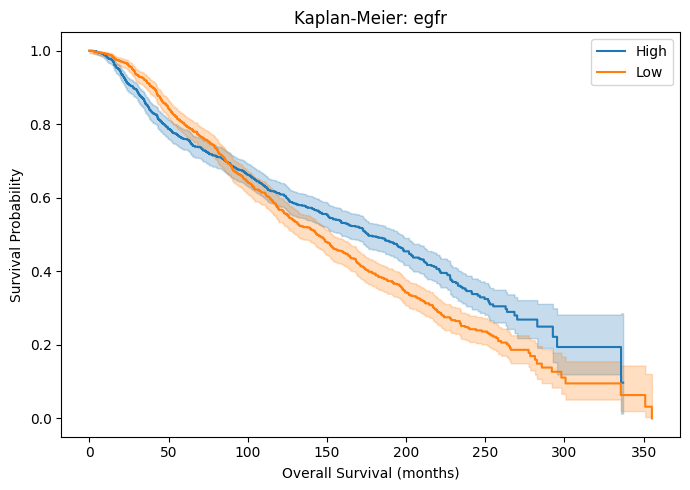

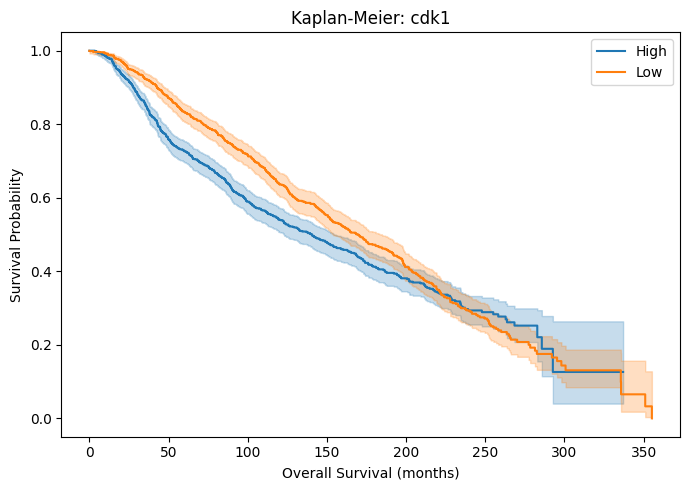

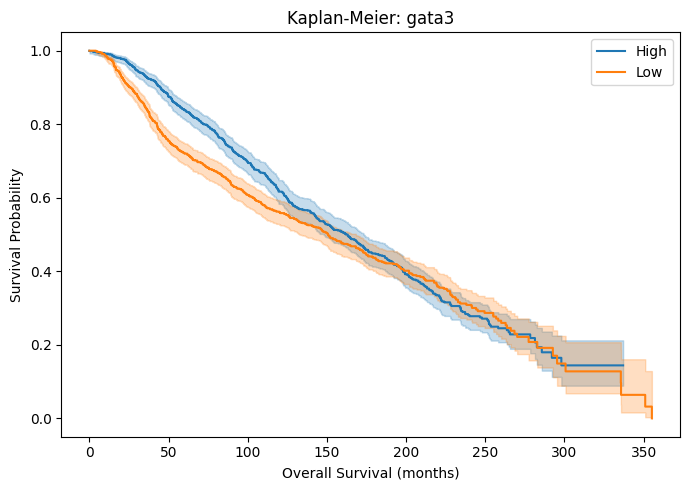

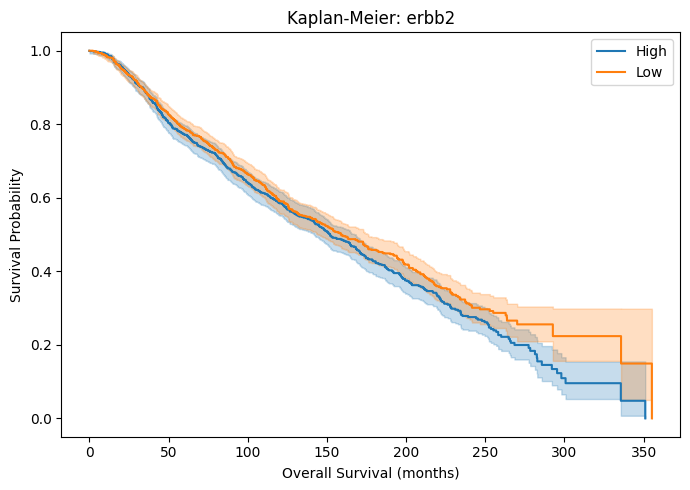

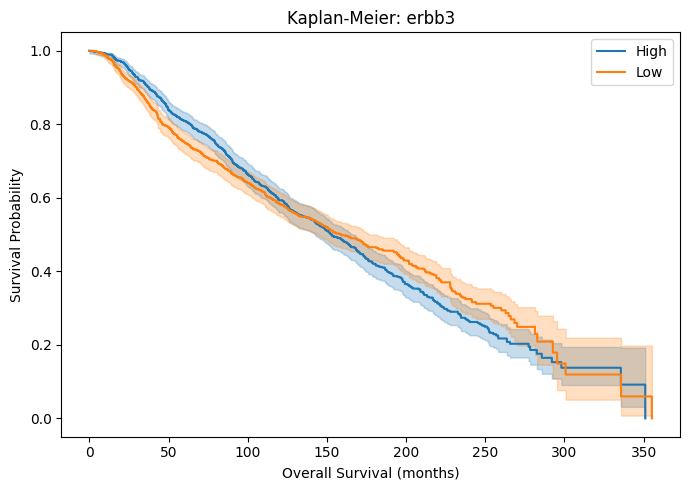

In [ ]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()

for gene in top5_genes:

    temp = survival_data[
        [gene, SURVIVAL_TIME, "event"]
    ].dropna().copy()

    median_value = temp[gene].median()

    temp["group"] = np.where(
        temp[gene] >= median_value,
        "High",
        "Low"
    )

    plt.figure(figsize=(7, 5))

    for group in ["High", "Low"]:

        group_data = temp[
            temp["group"] == group
        ]

        kmf.fit(
            group_data[SURVIVAL_TIME],
            group_data["event"],
            label=group
        )

        kmf.plot_survival_function()

    plt.title(f"Kaplan-Meier: {gene}")
    plt.xlabel("Overall Survival (months)")
    plt.ylabel("Survival Probability")
    plt.tight_layout()
    plt.show()

In [ ]:
y_pred = xgb.predict(X_test_imp)

accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Subtype Classification Results")
print("================================")
print(f"Accuracy : {accuracy:.4f}")
print(f"Macro F1 : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

Subtype Classification Results
Accuracy : 0.8346
Macro F1 : 0.6780

Classification Report:
              precision    recall  f1-score   support

       Basal       0.88      0.90      0.89        40
        Her2       0.84      0.84      0.84        44
        LumA       0.83      0.90      0.87       136
        LumB       0.84      0.86      0.85        92
          NC       0.00      0.00      0.00         1
      Normal       0.67      0.36      0.47        28
 claudin-low       0.85      0.82      0.84        40

    accuracy                           0.83       381
   macro avg       0.70      0.67      0.68       381
weighted avg       0.83      0.83      0.83       381



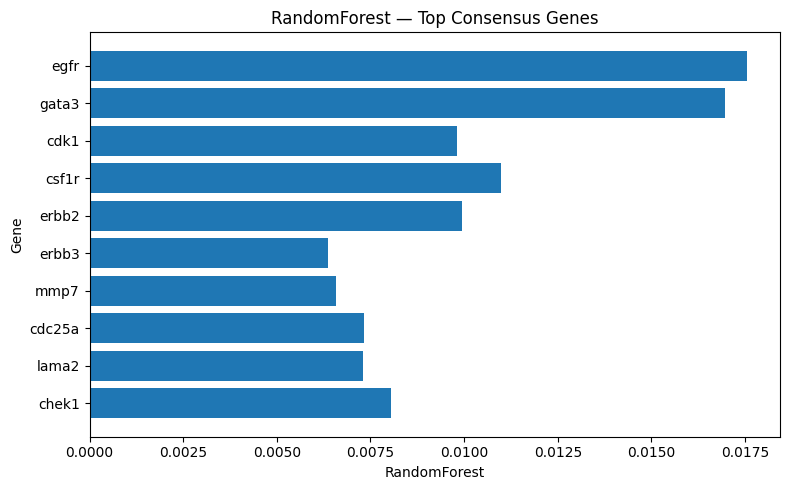

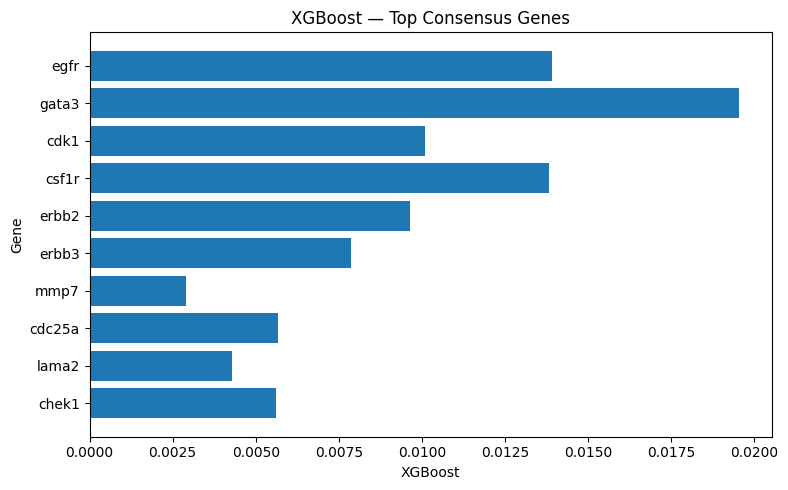

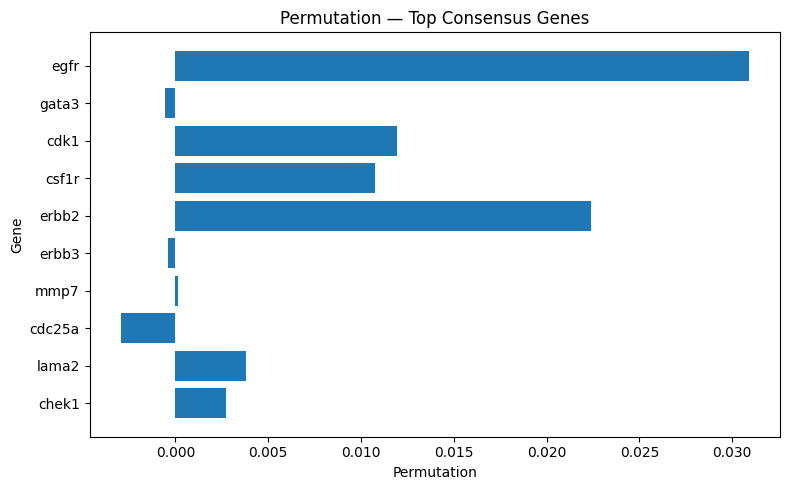

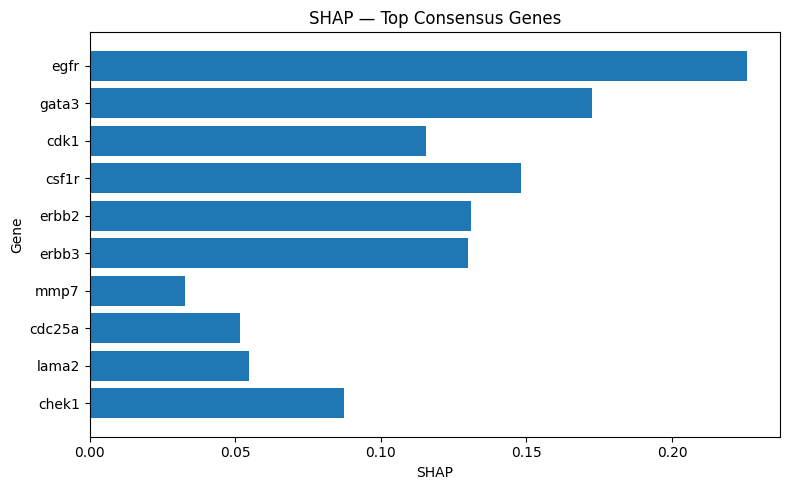

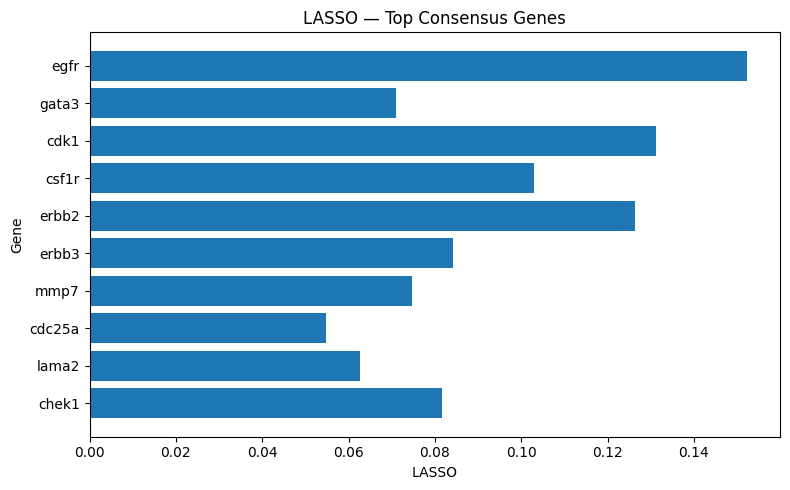

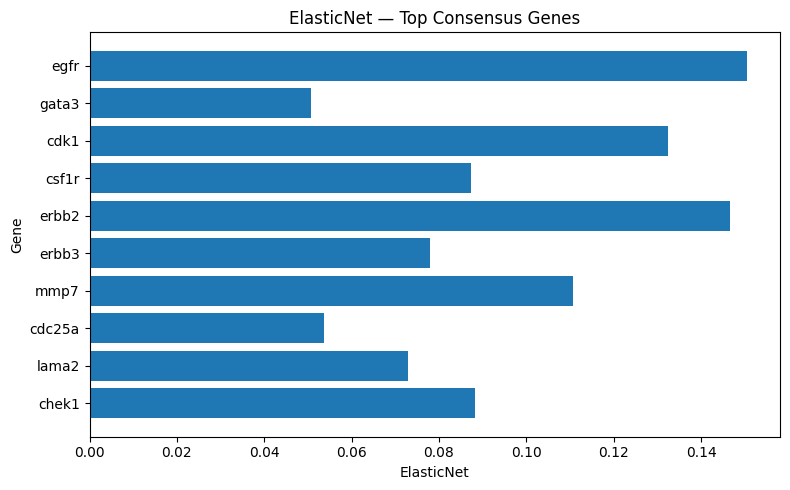

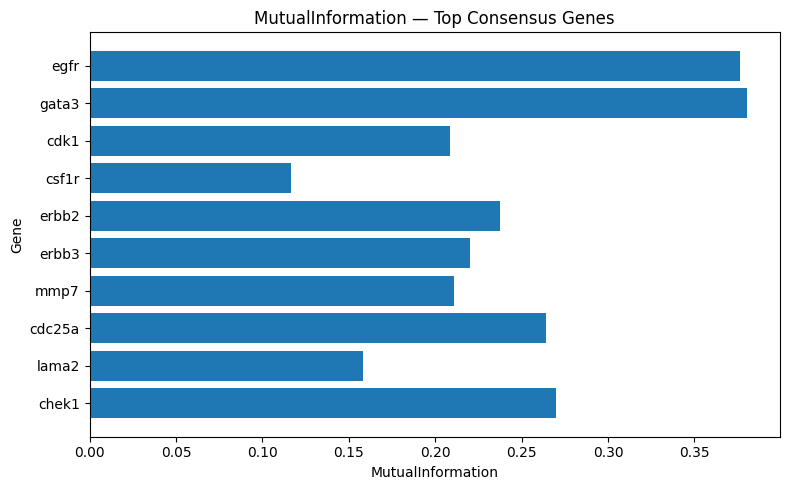

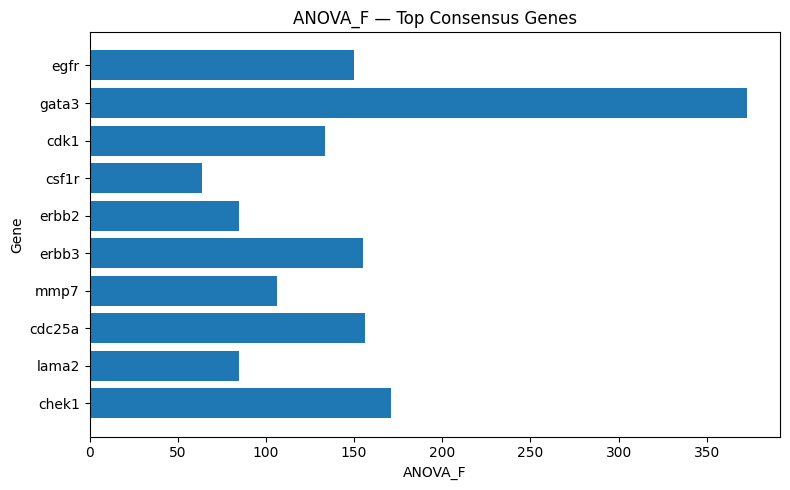

In [ ]:
top10 = importance_df.head(10).copy()

plot_columns = [
    "RandomForest",
    "XGBoost",
    "Permutation",
    "SHAP",
    "LASSO",
    "ElasticNet",
    "MutualInformation",
    "ANOVA_F"
]

for method in plot_columns:

    values = top10.sort_values(
        "Consensus_Score"
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        values["feature"],
        values[method]
    )

    plt.xlabel(method)
    plt.ylabel("Gene")
    plt.title(f"{method} — Top Consensus Genes")

    plt.tight_layout()
    plt.show()

In [ ]:
final_results = pd.DataFrame({
    "Metric": [
        "Number of patients",
        "Number of gene features",
        "Top genes selected",
        "Clinical-only C-index",
        "Clinical + Top 5 C-index",
        "Delta C-index",
        "Subtype Accuracy",
        "Subtype Macro F1"
    ],
    "Value": [
        len(df),
        len(gene_features),
        ", ".join(top5_genes),
        round(clinical_cindex, 4),
        round(genomic_cindex, 4),
        round(delta_cindex, 4),
        round(accuracy, 4),
        round(f1, 4)
    ]
})

display(final_results)

,Metric,Value
0,Number of patients,1904
1,Number of gene features,490
2,Top genes selected,"egfr, cdk1, gata3, erbb2, erbb3"
3,Clinical-only C-index,0.6834
4,Clinical + Top 5 C-index,0.6855
5,Delta C-index,0.0021
6,Subtype Accuracy,0.8346
7,Subtype Macro F1,0.678


In [ ]:
output_path = "/content/METABRIC_Final_Results.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:

    importance_df.to_excel(
        writer,
        sheet_name="All_Feature_Importance",
        index=False
    )

    importance_df.head(5).to_excel(
        writer,
        sheet_name="Top_5_Genes",
        index=False
    )

    clinical_cph.summary.to_excel(
        writer,
        sheet_name="Clinical_Cox"
    )

    genomic_cph.summary.to_excel(
        writer,
        sheet_name="Genomic_Cox"
    )

    final_results.to_excel(
        writer,
        sheet_name="Final_Results",
        index=False
    )

print("Excel file created:")
print(output_path)

Excel file created:
/content/METABRIC_Final_Results.xlsx
